##### <center>Beyond global density in a stochastic sandpile: the role of spatial signatures in the predictability of extremes</center>
<center>K.P. Orzechowski, J. Sienkiewicz & P. Fronczak</center> <br>
<center>Workbook 5: Modes R2</center>

---

Shape of the signal: cosine modes and the precursor R2. The modes are computed on raw images. The pair of modes is selected on the training set, and the remaining numbers come from the test set.

---

In [1]:
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle
from matplotlib.ticker import MaxNLocator

sys.path.insert(0, "../data_management")
import M5_Modes_R2 as m

pd.set_option("display.max_columns", None)
SIZES = (32, 64, 128)

BG, TEXT, LABEL, GRAY, AXIS = "#ffffff", "#0b0b0b", "#52514e", "#898781", "#c3c2b7"
plt.rcParams["pdf.fonttype"] = 42

#### Modes on the training set

In [3]:
modes = {L: m.mode_analysis(L) for L in SIZES}
m.table(modes, skip=("auc_map", "ranking"))

,identities.train.err_a00,identities.train.err_parseval,identities.test.err_a00,identities.test.err_parseval,identities.err_sum_R,pair.auc_20,pair.auc_02,pair.in_top_two
32,1.065814e-14,5.684342e-13,1.065814e-14,5.684342e-13,2.220446e-16,0.737366,0.742415,True
64,2.131628e-14,2.273737e-12,2.131628e-14,2.273737e-12,2.220446e-16,0.747606,0.763739,True
128,4.263256e-14,9.094947e-12,4.263256e-14,9.094947e-12,2.220446e-16,0.772064,0.763087,True


#### Modes with the highest AUC

In [4]:
pd.concat({L: pd.DataFrame(modes[L]["ranking"]) for L in SIZES})

m   n       auc
32  0   0   2  0.742415
    1   2   0  0.737366
    2   4   0  0.560843
    3   0   4  0.559966
    4   2   2  0.545259
    5   0   1  0.538576
    6   1   0  0.531807
    7   0   6  0.528995
64  0   0   2  0.763739
    1   2   0  0.747606
    2   0   4  0.571880
    3   4   0  0.568976
    4   2   2  0.549737
    5   2   4  0.535310
    6   0   1  0.535008
    7   6   0  0.530646
128 0   2   0  0.772064
    1   0   2  0.763087
    2   0   4  0.585890
    3   2   2  0.580471
    4   4   0  0.580297
    5   1   2  0.538897
    6   3   0  0.535101
    7  12  74  0.534913

#### Figure 3

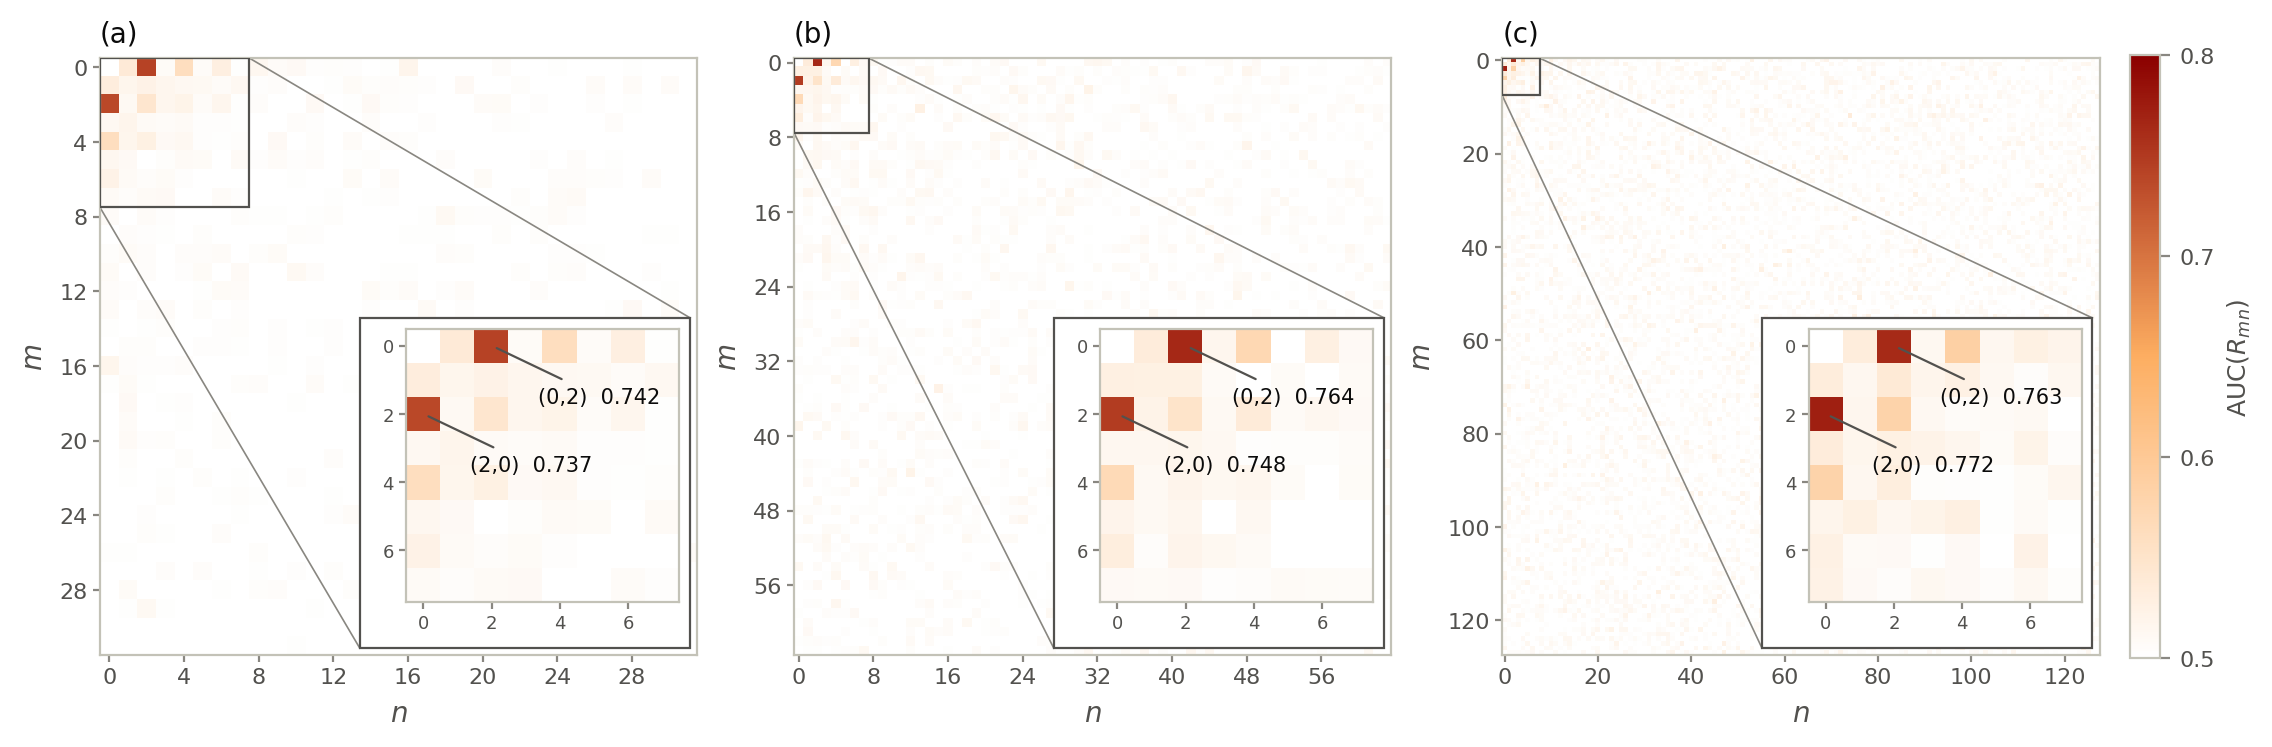

In [5]:
ZOOM = 8
CARD = (0.435, 0.012, 0.553, 0.553)
maps = {L: modes[L]["auc_map"] for L in SIZES}
norm = Normalize(vmin=0.5, vmax=0.8)
cmap = LinearSegmentedColormap.from_list("reds", [BG, "#fdae61", "darkred"])
cmap.set_under(BG)
cmap.set_bad(BG)

fig, axes = plt.subplots(1, 3, figsize=(3.55 * 3 + 0.6, 3.85), dpi=200, layout="constrained", facecolor=BG)
for ax, L, letter in zip(axes, SIZES, "abc"):
    x0, y0, width, height = CARD
    inset = ax.inset_axes([x0 + 0.078, y0 + 0.078, width - 0.078 - 0.018, height - 0.078 - 0.018], zorder=5)
    image = ax.imshow(maps[L], cmap=cmap, norm=norm, interpolation="nearest")
    inset.imshow(maps[L][:ZOOM, :ZOOM], cmap=cmap, norm=norm, interpolation="nearest")
    for mode_axes, fontsize, nticks in ((ax, 8, 8), (inset, 6.5, 4)):
        mode_axes.set_facecolor(BG)
        mode_axes.xaxis.set_major_locator(MaxNLocator(integer=True, nbins=nticks))
        mode_axes.yaxis.set_major_locator(MaxNLocator(integer=True, nbins=nticks))
        mode_axes.xaxis.set_major_formatter("{x:.0f}")
        mode_axes.yaxis.set_major_formatter("{x:.0f}")
        mode_axes.spines[:].set(color=AXIS, linewidth=0.8)
        mode_axes.tick_params(color=GRAY, labelcolor=LABEL, labelsize=fontsize, length=2.5, width=0.8, pad=2)

    ax.set_title(f"({letter})", loc="left", fontsize=10, color=TEXT, pad=6)
    ax.set_xlabel("$n$", fontsize=10, color=LABEL)
    ax.set_ylabel("$m$", fontsize=10, color=LABEL)
    ax.add_patch(Rectangle((-0.5, -0.5), ZOOM, ZOOM, fill=False, edgecolor=LABEL, linewidth=0.8, zorder=3))
    ax.add_patch(Rectangle((x0, y0), width, height, transform=ax.transAxes, facecolor=BG, edgecolor=LABEL, linewidth=0.8, zorder=4))
    ax.add_line(Line2D([ZOOM / L, x0 + width], [1.0, y0 + height], transform=ax.transAxes, color=GRAY, linewidth=0.6, zorder=2))
    ax.add_line(Line2D([0.0, x0], [1.0 - ZOOM / L, y0], transform=ax.transAxes, color=GRAY, linewidth=0.6, zorder=2))
    for mode_m, mode_n in m.PAIR:
        inset.annotate(f"({mode_m},{mode_n})  {maps[L][mode_m, mode_n]:.3f}", xy=(mode_n, mode_m), xytext=(mode_n + ZOOM * 0.17, mode_m + ZOOM * 0.21),
                       fontsize=7.5, color=TEXT, arrowprops=dict(arrowstyle="-", color=LABEL, lw=0.8))

cbar = fig.colorbar(image, ax=axes, shrink=0.8, pad=0.015)
cbar.set_label(r"AUC$(R_{mn})$", fontsize=9, color=LABEL)
cbar.outline.set_edgecolor(AXIS)
cbar.set_ticks([0.5, 0.6, 0.7, 0.8])
cbar.ax.yaxis.set_major_formatter("{x:.1f}")
cbar.ax.tick_params(color=GRAY, labelcolor=LABEL, labelsize=8)

fig.savefig("../data_repository/figures/fig_modes.png", bbox_inches="tight")
fig.savefig("../data_repository/figures/fig_modes.pdf", bbox_inches="tight")
plt.close(fig)
display(Image("../data_repository/figures/fig_modes.png"))

#### R2 against density on the test set (Table 5)

In [6]:
test = {L: m.check_on_test(L) for L in SIZES}
m.table(test, skip=("direction",))

,spearman_R2_q,spearman_R2_q_positives,spearman_R2_q_negatives,auc_R2,auc_R2_fixed_n,positives_coverage_n,auc_q_fixed_n
32,0.320368,-0.363563,-0.143682,0.825981,0.922397,0.947089,0.5
64,0.187872,-0.427006,-0.216356,0.851745,0.951327,0.871945,0.5
128,0.013828,-0.478322,-0.246843,0.856476,0.969507,0.782277,0.5


#### Direction of the contrast (Appendix C)

In [7]:
m.table({L: test[L]["direction"] for L in SIZES})

,positives.center_fraction_s20,positives.center_fraction_s02,positives.center_fraction_both,negatives.center_fraction_s20,negatives.center_fraction_s02,negatives.center_fraction_both,overload_ratio
32,0.975086,0.978293,0.953503,0.8729,0.8731,0.7592,1.847693
64,0.995987,0.994163,0.990150,0.9504,0.9487,0.9015,1.623541
128,0.998472,1.000000,0.998472,0.9915,0.9908,0.9823,1.449356


#### Relation of R2 to the scale of the signal (Appendix C)

In [8]:
scale = {L: m.relation_to_scale(L) for L in SIZES}
m.table(scale)

,test.auc_R2,test.auc_V4,test.spearman_V4_R2,test.auc_R2_in_blocks_L/8,test.auc_R2_in_blocks_L/4,test.auc_R2_in_blocks_L/2
32,0.825981,0.691045,0.527517,0.805456,0.732712,0.502873
64,0.851745,0.744001,0.552382,0.826582,0.758473,0.507932
128,0.856476,0.781450,0.607027,0.830620,0.762718,0.492768
